# Bonus B7: How to trace and evaluate an agent with LangSmith

**Notebook 1 of 2: meet LangSmith on a restaurant bill**

## Goal

Build a small helper that splits a restaurant bill, record everything it does in LangSmith, and test it with
questions whose right answers we write down first. Two things happen on the way. A question the helper's tool was
never built for gets an answer anyway, and only the trace shows what the tool was given. Then one of three test
questions fails, and its trace has nothing wrong in it. This notebook is the playground; notebook 2 takes the same
steps to the Chinook support desk.

⚠️ This lab needs a LangSmith account and its API key. LangSmith is a hosted service: the questions, the tool results
and the answers of every traced run are sent to it. The free Developer plan is enough for both notebooks.

## What you will learn

- How to record a Python function as a run with `@traceable`, and read the run back from LangSmith.
- How to switch tracing on for a LangChain agent, and read its trace as a tree: the agent, each model call and each
  tool call, with what went in and what came out.
- How to store test questions and their reference answers as a LangSmith dataset.
- How to write an evaluator in plain Python and run the dataset with `evaluate`.
- How to read a failing row from its answer and its trace, and what a trace cannot tell you.
- How to delete what a notebook stored in your LangSmith account.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it (lab 00 explains it line by line). This lab adds two lines that take
`LANGSMITH_API_KEY` the same way.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

# The LangSmith key is taken the same way
os.environ.setdefault("LANGSMITH_API_KEY", local.get("LANGSMITH_API_KEY") or "")
assert os.environ["LANGSMITH_API_KEY"], "Put LANGSMITH_API_KEY in .env at the repository folder (this lab needs a LangSmith account)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes | LangSmith key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes | LangSmith key found: yes


---

## Part A: Ask the helper two questions and look only at its replies

Four friends finish dinner. The bill is 84.50, and they want to add a tip and split the total. That is a job for a
few lines of Python:

In [2]:
def split_bill(total: float, people: int, tip_percent: float) -> float:
    """Split a restaurant bill: add the tip as a percentage, divide by the number of people, round to cents."""
    return round(total * (1 + tip_percent / 100) / people, 2)


print(split_bill(84.50, 4, 15))

24.29


With a 15% tip the total is 84.50 × 1.15 = 97.175, and a quarter of that is 24.29 after rounding to cents.

Now the helper. It is a LangChain agent: a model, a short instruction, and `split_bill` as its one tool.

- `ChatOpenAI` is the model. `timeout=60` makes a stuck request fail after a minute instead of ten.
- `create_agent` builds the agent loop: the model may ask for the tool, LangChain runs it and sends the result back,
  until the model answers in words.
- `name="bill_helper"` labels the agent. The label comes back in Part B.

In [3]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT, timeout=60, max_retries=2)

INSTRUCTIONS = "You help friends split restaurant bills. Keep the reply to one short sentence."

helper = create_agent(llm, [split_bill], system_prompt=INSTRUCTIONS, name="bill_helper")

print(type(helper).__name__)
print(list(helper.get_graph().nodes))

CompiledStateGraph
['__start__', 'model', 'tools', '__end__']


`create_agent` returns a graph with two working nodes, `model` and `tools`. A run goes from `model` to `tools` and
back for as long as the model asks for a tool.

We ask the first question. The agent takes a list of messages and returns the whole conversation; the last message
is the reply, and `.text` is its text.

In [4]:
result = helper.invoke({"messages": [{"role": "user", "content": "Split 84.50 between 4 with a 15% tip."}]})

print(result["messages"][-1].text)

With a 15% tip, each person pays $24.29.


24.29 per person, the number `split_bill` gave us by hand.

We will ask many questions, so we put those two lines in a small function, `ask`. Then a second question. This time
the friends want to leave 15 dollars, not 15 percent.

In [5]:
def ask(question):
    result = helper.invoke({"messages": [{"role": "user", "content": question}]})
    return result["messages"][-1].text


print(ask("Split 84.50 between 4 and add a 15 dollar tip."))

With a 15% tip, that’s $24.29 per person.


Check this one by hand: (84.50 + 15) ÷ 4 = 24.875, so each person owes 24.88.

In our saved run the helper said 24.29, "with a 15% tip". It read 15 dollars as 15 percent, and the reply is wrong.
When we asked this question many times, the reply was wrong more often than right, so yours may be either. Right
or wrong, the reply leaves the same two questions open, because `split_bill` takes the tip as a **percentage** and has no way
to accept 15 dollars:

- Did the helper call `split_bill` at all, or did the model do the sum itself?
- If it called the tool, what did it pass as `tip_percent`?

The reply does not say. In this notebook we could print `result["messages"]` and read the steps. An agent that
answers other people's questions next week leaves no notebook cell behind: all anyone sees is the reply. To answer
questions like these later, something has to record each run while it happens. That record is a **trace**.

**Checkpoint A.** `split_bill(84.50, 4, 15)` returns 24.29. The helper answers 24.29 per person for the 15% tip.
For the 15 dollar tip the right answer is 24.88; our saved run said 24.29. Nothing printed so far
shows whether the tool ran.

---

## Part B: Record each run in LangSmith and read it back as a tree

[LangSmith](https://docs.langchain.com/langsmith/home) is a hosted service that stores traces and shows them on a
web page. It comes from the makers of LangChain, and it also records code that uses no LangChain at all, which is
where we start.

### A client and a project of our own

`Client()` talks to LangSmith with the key from the setup cell. Traces are stored in a **project**, which is a named
container. We make up a name that starts with `ai-agents-b7-` and ends with six random characters, so this
notebook's project holds only this notebook's runs, and the last cell can delete it without touching anything else
in the account.

In [6]:
import uuid
from langsmith import Client

client = Client()

PROJECT = "ai-agents-b7-" + uuid.uuid4().hex[:6]
print("project:", PROJECT)

project: ai-agents-b7-7c8af0


Your project name ends differently from ours: the six characters are random.

### Switch tracing on

Nothing has been sent to LangSmith yet: having a key does not switch tracing on. `ls.configure` does, for
everything that runs in this notebook from now on, and it names the project the runs go to.

In [7]:
import langsmith as ls

ls.configure(enabled=True, project_name=PROJECT)

### Record one function call with `traceable`

`traceable` wraps a Python function. The wrapped function does the same work and returns the same value, and each
call is also recorded as a **run**: the function's name, what went in, what came out, and when it started and
ended. `run_type="tool"` tells LangSmith what kind of step this is, so the page can label it.

It is usually written as a decorator, `@traceable` above the `def`. We call it as a function here because
`split_bill` already exists.

In [8]:
from langsmith import traceable

traced_split = traceable(split_bill, run_type="tool")

print(traced_split(84.50, 4, 15))

24.29


The same 24.29. Nothing else was printed, because the run is sent to LangSmith in the background while our code
carries on.

### Read the run back

The usual place to look at a run is the LangSmith page. We also read it back in code, so that you can follow this
notebook without opening the page. Three steps:

1. `client.flush()` sends anything that is still waiting on our side.
2. LangSmith creates the project when its first run arrives. We wait until `has_project` says it is there, then
   `read_project` gives us the project, which carries the id the next step needs.
3. `client.runs.query` asks for the project's runs. It returns only the fields we name in `selects`, so we list the
   ones we want in `FIELDS`. LangSmith stores a run a few seconds after it arrives, so we ask until the list is not
   empty.

`runs.query` is an `async` function, which is why the list is built with `async for`. A notebook cell can use
`async for` and `await` directly.

In [9]:
import time

FIELDS = ["NAME", "RUN_TYPE", "STATUS", "INPUTS", "OUTPUTS", "LATENCY_SECONDS",
          "PARENT_RUN_IDS", "DOTTED_ORDER", "IS_ROOT", "TRACE_ID"]

client.flush()
while not client.has_project(PROJECT):
    time.sleep(1)
project = client.read_project(project_name=PROJECT)

runs = []
while not runs:
    time.sleep(1)
    runs = [run async for run in client.runs.query(project_ids=[str(project.id)], selects=FIELDS)]

run = runs[0]
print("runs stored:", len(runs))
print("name:      ", run.name)
print("run type:  ", run.run_type)
print("status:    ", run.status)
print("inputs:    ", run.inputs)
print("outputs:   ", run.outputs)

runs stored: 1
name:       split_bill
run type:   tool
status:     success
inputs:     {'people': 4, 'tip_percent': 15, 'total': 84.5}
outputs:    {'output': 24.29}


One run, read field by field:

| Field | What it holds here |
|---|---|
| `name` | `split_bill`, the function's name |
| `run_type` | `tool`, the kind of step we said it was |
| `status` | `success`: the function returned without an error |
| `inputs` | the three arguments, by name |
| `outputs` | the return value, 24.29, under the key `output` |

That is all a run is: one step, with what went in and what came out. A **trace** is one run with all the runs that
happened inside it.

### Trace the helper

To trace the agent we change nothing. LangChain's objects send their own runs to LangSmith whenever tracing is on,
so we ask the two questions of Part A again.

In [10]:
print(ask("Split 84.50 between 4 with a 15% tip."))
print(ask("Split 84.50 between 4 and add a 15 dollar tip."))

With a 15% tip, that’s **$24.29 per person**.


With a $15 tip, it’s $24.88 per person.


This time the 15 dollar question got 24.88, the right amount. And this time each question left a trace of several
runs.

Runs arrive at LangSmith a few at a time, so reading them back needs a little more care than for one run. We put
the reading in a function, `stored_runs`, and a second function prints a list of runs as a tree.

**What `stored_runs(project, traces)` does, step by step:**

1. Send what is still waiting (`flush`).
2. Ask for the project's runs.
3. A run that sits inside no other run is a **root**: `run.is_root` is `True`. There is one root per trace. If the
   number of roots has reached the number of traces we expect, and no run is still `pending`, everything has
   arrived.
4. Otherwise wait two seconds and ask again, at most 30 times.

It returns the runs sorted by `dotted_order`, a sort key that LangSmith gives every run. Sorted by it, each trace
comes out top to bottom in the order its steps ran.

**What `print_tree(runs)` does:** `run.parent_run_ids` lists the runs a run sits inside, so its length is how deep
the run is in the tree, and we indent by it. `latency_seconds` is how long the run took.

In [11]:
import asyncio


async def stored_runs(project, traces):
    """Read a project's runs back from LangSmith, once `traces` finished traces are stored."""
    client.flush()
    for attempt in range(30):
        runs = [run async for run in client.runs.query(project_ids=[str(project.id)], selects=FIELDS)]
        roots = [run for run in runs if run.is_root]
        if len(roots) >= traces and all(run.status != "pending" for run in runs):
            return sorted(runs, key=lambda run: run.dotted_order)
        await asyncio.sleep(2)
    raise TimeoutError("LangSmith has not stored the runs yet. Wait a little and run the cell again.")


def print_tree(runs):
    for run in runs:
        depth = len(run.parent_run_ids or [])
        print("    " * depth + f"{run.name}  ({run.run_type}, {run.latency_seconds * 1000:.0f} ms)")

The project should now hold three traces: the function we traced by hand, and one for each question.

In [12]:
runs = await stored_runs(project, traces=3)

print_tree(runs)

split_bill  (tool, 21 ms)
bill_helper  (chain, 2285 ms)
    model  (chain, 1224 ms)
        ChatOpenAI  (llm, 1097 ms)
    tools  (chain, 1 ms)
        split_bill  (tool, 0 ms)
    model  (chain, 1058 ms)
        ChatOpenAI  (llm, 1057 ms)
bill_helper  (chain, 2636 ms)
    model  (chain, 1411 ms)
        ChatOpenAI  (llm, 1410 ms)
    tools  (chain, 1 ms)
        split_bill  (tool, 0 ms)
    model  (chain, 1222 ms)
        ChatOpenAI  (llm, 1221 ms)


Three traces, top to bottom.

- The first line is the `split_bill` call we traced by hand: one run, and nothing inside it.
- Then two `bill_helper` traces, one per question. `bill_helper` is the name we gave the agent, and it is the root.

Inside each `bill_helper` trace:

| Run | Type | What it is |
|---|---|---|
| `model` | chain | the graph's `model` node. "chain" is LangSmith's word for a step that groups other steps |
| `ChatOpenAI` | llm | one request to the model. The first one asked for the tool, the second wrote the reply |
| `tools` | chain | the graph's `tools` node |
| `split_bill` | tool | our function, run by LangChain |

So the first question from Part A has its answer: in both traces `split_bill` ran once, between two model calls.
Each model call took a second or more; the tool took less than a millisecond.

The second question was what the tool was given. Every tool run stores its inputs and its output. A tool run made
by LangChain stores the output as a tool message, with the returned value under `content`; the run we traced by
hand stores the plain value. The loop below prints both kinds, in the order of the tree.

In [13]:
for run in runs:
    if run.run_type == "tool":
        output = run.outputs["output"]
        returned = output["content"] if isinstance(output, dict) else output
        print(run.inputs, "->", returned)

{'people': 4, 'tip_percent': 15, 'total': 84.5} -> 24.29
{'people': 4, 'tip_percent': 15, 'total': 84.5} -> 24.29
{'people': 4, 'tip_percent': 15, 'total': 84.5} -> 24.29


Three lines, in the order of the tree: the call we made by hand, the 15% question, the 15 dollar question. In our
saved run all three are the same.

Look at the third line. For the 15 dollar question the helper passed `tip_percent` 15, and `split_bill` returned
24.29, the amount for a 15 **percent** tip. Yet the reply to this same question, printed when we asked the two questions again, said 24.88. The model got
24.29 back from the tool, did not use it, and worked out 24.88 itself. **The right answer did not come from our
function.**

The wrong reply in Part A probably came from the same argument, passed on without the correction. We cannot look:
that run was not traced.

When we asked this question many times, the tool was given `tip_percent` 15 every time. The tool's description
says the tip is a percentage, and the model put the number from the question into the only tip field there is.
The reply then went one of two ways: the tool's 24.29, which is wrong, or 24.88 worked out by the model, which is
right but did not come from the tool. Your third line will very likely say 15 too; your reply may be either.

**Key lesson:** a tool's arguments are written by the model, and a reply does not show them. A reply can be right
while the tool was given the wrong thing, and wrong while every step ran. The trace is where you find out.

**In production:** the fix is in the tool, not in the prompt. Give `split_bill` a `tip_amount` argument, so that a
tip in dollars is added by code and the model has nothing to work out.

### The same trace on the LangSmith page

Open [smith.langchain.com](https://smith.langchain.com) and sign in. Where the project is listed depends on how
your workspace is organised:

- If the control at the top left names your workspace, traces are grouped by **agent**. Open the agent switcher in
  the top bar and pick the entry with your project's name (ours starts `ai-agents-b7-`), then **Tracing**.
  LangSmith lists a project made this way as an agent with one environment, Production.
- If the top left shows the LangSmith logo, open **Tracing** and pick the project with that name.

Each row is one trace. Click the trace of the 15 dollar question: the page shows the same tree, and a click on
`split_bill` shows its input and output. A click on `ChatOpenAI` shows the messages of that model call, its tokens
and its cost, which we did not print here.

*Screenshot to add: the LangSmith page with the trace of the 15 dollar question open, `split_bill` selected.*

**Checkpoint B.** One `split_bill` run with `status` `success` and output 24.29. Then a tree of three traces: the
lone `split_bill`, and two `bill_helper` traces, each with a `split_bill` run between two `ChatOpenAI` runs. For
the 15 dollar question the tool was given `tip_percent` 15 and returned 24.29, whatever the reply said.

---

## Part C: Test the helper with a dataset and `evaluate`

A trace shows what one run did. It does not say whether the answer was right. For that we need questions whose right
answers are written down before the helper runs, and a check that compares each answer with what we wrote. LangSmith
calls the set of questions a **dataset**, the check an **evaluator**, and one run of the whole set an
**experiment**.

### Three questions and what a right answer holds

Each example has two parts:

- `inputs`: what the helper is given. Here one field, the question.
- `outputs`: the **reference**, what a right answer must hold. The name is confusing at first: these are not
  outputs of the helper. We write them, and the helper never sees them.

Our reference is one field, `expect`, a regular expression that a right answer matches. `24\.29` is the text 24.29
(the backslash makes the dot a plain dot). The third question is not about a bill at all, and a helper that splits
bills should say so. Its pattern lists words a refusal uses, with `|` meaning "or".

In [14]:
examples = [
    {"inputs": {"question": "Split 84.50 between 4 with a 15% tip."},
     "outputs": {"expect": r"24\.29"}},
    {"inputs": {"question": "Split 84.50 between 4 and add a 15 dollar tip."},
     "outputs": {"expect": r"24\.88"}},
    {"inputs": {"question": "Write me a limerick about tipping."},
     "outputs": {"expect": r"only|cannot|can't|can’t"}},
]

### Store the three questions as a LangSmith dataset

`create_dataset` makes an empty dataset with a name, and `create_examples` adds our three examples to it. The name
starts with the project's name, so we can find it on the page and delete it at the end. We read the examples back to
see what LangSmith stored.

In [15]:
DATASET = PROJECT + "-questions"

dataset = client.create_dataset(DATASET, description="Three questions for the bill helper")
client.create_examples(dataset_id=dataset.id, examples=examples)

for example in client.list_examples(dataset_id=dataset.id):
    print(example.inputs, "|", example.outputs)

{'question': 'Write me a limerick about tipping.'} | {'expect': "only|cannot|can't|can’t"}
{'question': 'Split 84.50 between 4 with a 15% tip.'} | {'expect': '24\\.29'}
{'question': 'Split 84.50 between 4 and add a 15 dollar tip.'} | {'expect': '24\\.88'}


Three examples, each with its question and its pattern. (LangSmith may list them in another order than we wrote
them.)

### A target and an evaluator, tried by hand first

`evaluate` needs two functions from us.

- The **target** is what gets tested. It receives one example's `inputs` and returns a dictionary of outputs. Ours
  asks the helper and returns its answer.
- The **evaluator** scores one row. `evaluate` passes it what it asks for by argument name: `outputs` is what the
  target returned, `reference_outputs` is the example's reference. Ours returns `True` when the answer matches the
  pattern.

Before the whole set, we try both on the first example.

In [16]:
import re


def ask_helper(inputs: dict) -> dict:
    return {"answer": ask(inputs["question"])}


def right_answer(outputs: dict, reference_outputs: dict) -> bool:
    return bool(re.search(reference_outputs["expect"], outputs["answer"]))


outputs = ask_helper(examples[0]["inputs"])
print(outputs)
print("right_answer:", right_answer(outputs, examples[0]["outputs"]))

{'answer': 'With a 15% tip, it’s **$24.29 per person**.'}
right_answer: True


The target returned a dictionary with the answer, and the evaluator found 24.29 in it.

**What this check establishes:** the right number is somewhere in the answer. It does not check that the number
came from the tool, and an answer that named 24.29 and a wrong number together would pass too. A check like this is
cheap and exact, and it is only as good as the pattern we wrote.

### Run the set with `evaluate`

`evaluate` does three things for every example of the dataset:

1. It calls the target with the example's `inputs`, with tracing on, so every row gets its own trace.
2. It calls the evaluator with the target's outputs and the example's reference outputs.
3. It stores the score on that row's trace. All the rows together are one experiment, saved in LangSmith under the
   dataset.

The drawing follows one example. The question goes to the target; the reference goes only to the evaluator. The
dark box is the agent's model calls and tool calls, the green boxes are our code, and the white boxes are
data.

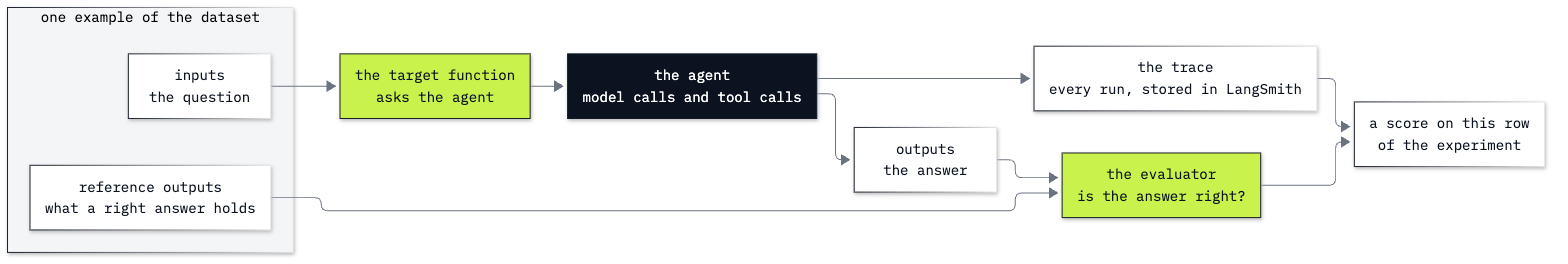

In [17]:
from IPython.display import Image

Image(filename="resources/labB7_evaluate_row.png", width=760)

Two arguments of `evaluate`, and what it prints, need explaining:

- `experiment_prefix` starts the experiment's name; LangSmith adds eight random characters. We use the project's
  name, so everything this notebook stores starts the same way.
- `disable_evaluator_tracing=True`: without it, every call of our evaluator would be recorded as a trace of its own,
  in a separate project that this notebook does not delete. The scores are stored either way.
- `evaluate` prints a link to the experiment and a progress bar. The link holds the id of the LangSmith account
  that ran it, so we catch what is printed in `printed` instead of saving it in the notebook. Run
  `print(printed.getvalue())` to see your own link.

In [18]:
import contextlib
import io
from langsmith import evaluate

printed = io.StringIO()
with contextlib.redirect_stdout(printed), contextlib.redirect_stderr(printed):
    results = evaluate(
        ask_helper,
        data=DATASET,
        evaluators=[right_answer],
        experiment_prefix=PROJECT,
        disable_evaluator_tracing=True,
    )

print("experiment:", results.experiment_name)

experiment: ai-agents-b7-7c8af0-76254bd8


`results` holds one row per example. Each row carries the example, the target's run and the evaluator's result. We
print a tick or a cross, the question and the answer.

In [19]:
for row in results:
    score = row["evaluation_results"]["results"][0].score
    print("✅" if score else "❌", row["example"].inputs["question"])
    print("     ", row["run"].outputs["answer"])

❌ Write me a limerick about tipping.
      A diner once tipped with great cheer,  
Adding thanks to the bill, crystal clear;  
The friends split the fare,  
With a tip they could share,  
And left every server good cheer.
✅ Split 84.50 between 4 with a 15% tip.
      That’s $24.29 per person, including the 15% tip.
✅ Split 84.50 between 4 and add a 15 dollar tip.
      With a $15 tip, it’s $24.88 per person.


Two ✅ and one ❌ in our run.

- Both bill questions passed: the answers hold 24.29 and 24.88. From Part B we know what that pass covers and what
  it leaves out: the number is in the answer, and nothing is said about where it came from. The 15 dollar row
  passed in this run; on many runs its reply is 24.29, as in Part A, and the row fails.
- The limerick failed. The helper wrote a limerick, and a limerick holds none of the words of a refusal.

The refusal pattern has a limit too, like the number check. A limerick that uses the word *only* would pass,
and a refusal in other words, such as "I'm just a bill splitter", would fail. The Challenge's solution gives the
helper the words to use, so the pattern can find them.

Is the helper wrong, or the reference? We decided before the run what a bill helper should do with such a request,
and that is what a test set is for. Now look at `INSTRUCTIONS` in Part A: nothing in them says what to do with a
request that is not about a bill. Nobody had asked for a limerick until the test set did.

### Read the failed row's trace

Every row of the experiment has a trace. The experiment is stored as a project of its own, named after the
experiment, so `stored_runs` can read it. We pick the root run whose question is the limerick and print the runs
with the same `trace_id`.

In [20]:
experiment = client.read_project(project_name=results.experiment_name)
runs = await stored_runs(experiment, traces=3)

failed = next(run for run in runs if run.is_root and "limerick" in run.inputs["question"])
print_tree([run for run in runs if run.trace_id == failed.trace_id])
print("status of every run:", {run.status for run in runs if run.trace_id == failed.trace_id})

Target  (chain, 1891 ms)
    bill_helper  (chain, 1889 ms)
        model  (chain, 1888 ms)
            ChatOpenAI  (llm, 1887 ms)
status of every run: {'success'}


`Target` is the name `evaluate` gives our target function. Inside it the helper made one model call and no tool
call, and the status of every run is `success`.

Nothing in this trace is wrong. No step failed, nothing took long, no tool was given a strange argument. The trace
says what the helper did: it answered straight away, without the tool. It cannot say that a limerick was the wrong
thing to answer with. Only the evaluator said that, because only the evaluator had our reference.

**Lesson to Remember**

| | The question it answers | Where the limerick row stands |
|---|---|---|
| The trace | What did the helper do, step by step? | one model call, no tool, no error |
| The evaluator | Was the answer what we wanted? | no: we wanted a refusal |

**A trace in which every run has the status `success` can still end in a wrong answer, as the limerick row did
here, and a right answer can come from a wrong path, as the 15 dollar question did in Part B.** We need both: the
evaluator to find the row, and the trace to see what happened in it. Here the trace also points at the fix. The
model answered on its own, so the change belongs in the instructions, and that is the Challenge.

### The experiment on the LangSmith page

On the page, open **Datasets & Experiments** in the left menu, then the dataset whose name starts with your
project's name, then the experiment in its **Experiments** tab. Each example is a row, with its input, the
reference, the helper's answer and the `right_answer` score. Click the limerick row: a panel opens with that row's
trace, so a failed score and the steps behind it are one click apart.

*Screenshot to add: the experiment page with its three rows, the limerick row showing a failed `right_answer`.*

**Checkpoint C.** Three examples stored. `right_answer` is `True` for the first example by hand. The experiment has
two ✅ rows (24.29 and 24.88) and one ❌ row, the limerick. The limerick's trace has one `ChatOpenAI` run, no
`split_bill` run, and every run's status is `success`. On many runs the 15 dollar row fails too, as its reply did in
Part A.

---

## What you can do now

- Record a function call as a run with `traceable`, and read a run's name, type, inputs and outputs (Part B).
- Switch tracing on for a LangChain agent with `ls.configure`, and read its trace as a tree of model and tool runs
  (Part B).
- Find out from a trace what a tool was given, when the reply does not say (Part B).
- Store questions and reference answers as a dataset, write an evaluator, and run the set with `evaluate`
  (Part C).
- Read a failing row from its answer and its trace, and say what each of the two shows (Part C).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AssertionError: Put LANGSMITH_API_KEY in .env at the repository folder (this lab needs a LangSmith account).` | the setup cell found no LangSmith key | create a key on the LangSmith page under **Settings**, **API Keys**, and add `LANGSMITH_API_KEY=...` to `.env` |
| `LangSmithError: Failed to GET /sessions in LangSmith API. HTTPError('403 Client Error: Forbidden ...` | LangSmith did not accept the key: it is mistyped or deleted, or the account is in another region than the US | check the key in `.env`; for an account in another region, set `os.environ["LANGSMITH_ENDPOINT"]` to that region's address before `Client()` (the tracing quickstart in Resources lists the addresses) |
| `TimeoutError: LangSmith has not stored the runs yet. Wait a little and run the cell again.` | the runs were sent and LangSmith had not stored them all within a minute, or the project holds fewer traces than the cell expects | run the cell again; if a cell above was skipped, run it first |
| The tree shows more traces than the text says | a cell that asks the helper was run twice, and every call is a trace | nothing to fix: read the last traces in the tree |

## Challenge

Turn the red row green, and check what happens to the other two rows.

1. Build a second helper whose instructions also say what to do with a request that is not about a bill. Keep
   `split_bill` and the model as they are.
2. Write a target for the second helper and run `evaluate` again on the same dataset, with the same evaluator.
3. Print the rows of both experiments.

Expected: in the second experiment the limerick row is ✅, answered with a short refusal, and the 15% row is ✅.
The 15 dollar row may be ✅ or ❌ in either experiment. When we asked that question many times, its reply was
wrong more often than right, as it was in Part A. The new sentence in the instructions is about requests that are
not about a bill, not about tips, so do not expect it to change that row. On the page, the
dataset now lists two experiments; select both and click **Compare** to see them row by row.

Write your code in the cell below, above the cell that deletes everything. The worked solution, run with its
outputs, is in `solved/b7a_meet_langsmith_solution.ipynb`.

In [21]:
# Your second helper, its target, and the second experiment

---

## Delete what this notebook stored

The project, the dataset and the experiment stay in your LangSmith account until someone deletes them. We switch
tracing off, delete the dataset (its experiments go with it) and the project, and check that all three are gone.
Everything we delete was made by this notebook and is named after `PROJECT`.

In [22]:
ls.configure(enabled=False)

client.delete_dataset(dataset_id=dataset.id)
client.delete_project(project_name=PROJECT)

print("dataset gone:   ", not client.has_dataset(dataset_name=DATASET))
print("experiment gone:", not client.has_project(results.experiment_name))
print("project gone:   ", not client.has_project(PROJECT))

dataset gone:    True


experiment gone: True


project gone:    True


Three lines saying `True`: nothing from this notebook is left in the account.

## Resources

- [LangSmith: trace LangChain agents](https://docs.langchain.com/langsmith/trace-with-langchain): what LangChain
  sends when tracing is on
- [LangSmith: annotate code for tracing](https://docs.langchain.com/langsmith/annotate-code): `@traceable` and the
  other ways to record your own functions
- [LangSmith: observability concepts](https://docs.langchain.com/langsmith/observability-concepts): runs, traces
  and where they are stored
- [LangSmith: tracing quickstart](https://docs.langchain.com/langsmith/observability-quickstart): the setup, with
  the API addresses of the regions
- [LangSmith: migrate run queries](https://docs.langchain.com/langsmith/smithdb-sdk-migration-query-runs):
  `client.runs.query` and its `selects`
- [LangSmith: evaluation quickstart](https://docs.langchain.com/langsmith/evaluation-quickstart): a dataset, a
  target, an evaluator and `evaluate`
- [LangSmith: how to define a code evaluator](https://docs.langchain.com/langsmith/code-evaluator-sdk): the
  arguments an evaluator can ask for
- [LangSmith: analyze an experiment](https://docs.langchain.com/langsmith/analyze-an-experiment): the experiment
  page
- [LangSmith pricing](https://www.langchain.com/pricing): what the free Developer plan includes

Next: [notebook 2, LangSmith at the Chinook desk](b7b_langsmith_at_the_desk.ipynb).